## Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.


### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?



In [ ]:
# code here

import pandas as pd  # Import pandas for data manipulation and analysis

df = pd.read_csv(r"C:\Users\BOSCO\Desktop\Ironhack\Week_2\Day_4\lab-eda-univariate\amz_uk_price_prediction_dataset.csv")

# 'pd.read_csv()' is a pandas function that reads a CSV (comma-separated values) file.
# The argument inside the parentheses is the file path — where the dataset is located on my computer.
# The 'r' before the quotes makes it a *raw string*, so Python doesn’t treat the backslashes '\' as escape characters.
# The data is then loaded into a variable called 'df' (DataFrame), which is a pandas data structure similar to an Excel table (rows and columns).


df.head() # '.head()' is a pandas method that shows the first 5 rows of the DataFrame by default.
          # This helps us quickly preview the dataset — see the column names, data types, and some sample values.
          # It doesn’t modify the data; it’s just for inspection.


category_counts = df["category"].value_counts()  # 'df["category"]' accesses a specific column of the DataFrame named 'category'.
                                                 # '.value_counts()' counts how many times each unique value appears in that column.
                                                 # The result is a pandas Series where:
                                                 # The index represents each category name
                                                 # The values represent how many times that category appears
                                                 # The result is stored in a new variable called 'category_counts'.

top5_categories = category_counts.head(5)        # '.head(5)' shows the first 5 entries from the 'category_counts' Series.
                                                 # Since 'value_counts()' sorts results in descending order by default,
                                                 # this will show the 5 most frequent categories in the dataset.

print("Top 5 most listed product categories:")   # prints string

print(top5_categories)                           # This prints the 'top5_categories' Series.
                                                 # Each line will show a category name and its count (number of times it appears in the dataset).


Top 5 most listed product categories:
category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

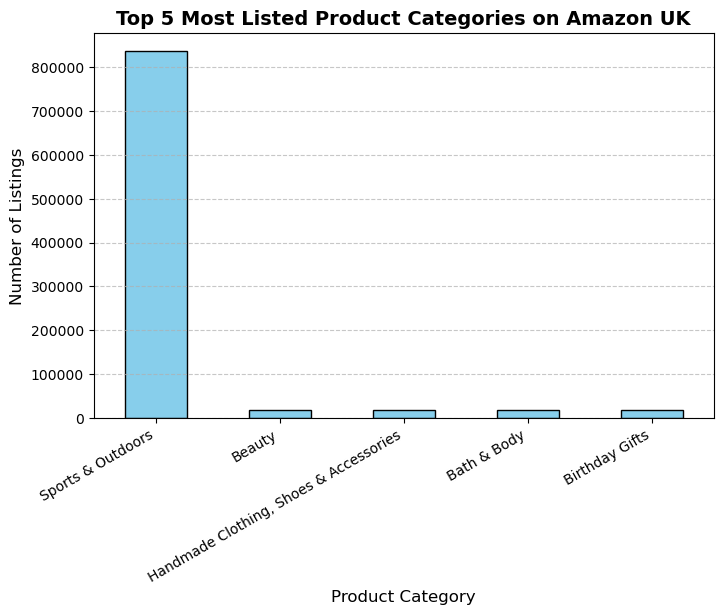

In [ ]:
import matplotlib.pyplot as plt   # Import the matplotlib library, which we use to create charts and visualizations.
                                  # Specifically, we’ll use its pyplot module (commonly called plt) for plotting.

top5_categories = df['category'].value_counts().head(5)  # Create a new variable containing the 5 most frequent categories in the dataset. (If not we wont be able to se the bar chart because it has too many values)
                                                         # df['category'] accesses the column named 'category'.
                                                         # .value_counts() counts how many times each unique category appears.
                                                         # .head(5) selects only the top 5 highest counts.

plt.figure(figsize=(8,5))  # Define the overall figure (the canvas) where the chart will be drawn.
                           # figsize=(8,5) sets the width to 8 inches and height to 5 inches.
                           # This makes the visualization large enough to read comfortably.

top5_categories.plot(kind='bar', color='skyblue', edgecolor='black')  # Plot a bar chart using the top 5 categories.
                                                                      # kind='bar' specifies a vertical bar chart.
                                                                      # color='skyblue' gives the bars a light blue color for visual appeal.
                                                                      # edgecolor='black' adds a black border around each bar to make them stand out.

plt.title('Top 5 Most Listed Product Categories on Amazon UK', fontsize=14, fontweight='bold')  # Add a descriptive title to the chart.
                                                                                                # fontsize=14 increases the font size.
                                                                                                # fontweight='bold' makes the title text thicker and easier to read.

plt.xlabel('Product Category', fontsize=12)      # It adds a label to the x-axis so the viewer knows what it represents.
                                                 # fontsize=12 makes it slightly smaller than the title but still readable.

plt.ylabel('Number of Listings', fontsize=12)    # It adds a label to the y-axis indicating that it shows the number of listings.

plt.xticks(rotation=30, ha='right')              # Rotate the category names on the x-axis to avoid overlap and improve readability.
                                                 # rotation=30 tilts the labels 30 degrees.
                                                 # ha='right' horizontally aligns the labels to the right, so they line up neatly.


plt.grid(axis='y', linestyle='--', alpha=0.7)    # Add horizontal gridlines to the background to make it easier to compare bar heights visually.
                                                 # axis='y' ensures the grid only appears along the y-axis (not vertical lines).
                                                 # linestyle='--' makes the lines dashed instead of solid.
                                                 # alpha=0.7 adjusts transparency so the lines don’t overpower the bars.


plt.show()



Subset of top categories, using a pie chart.

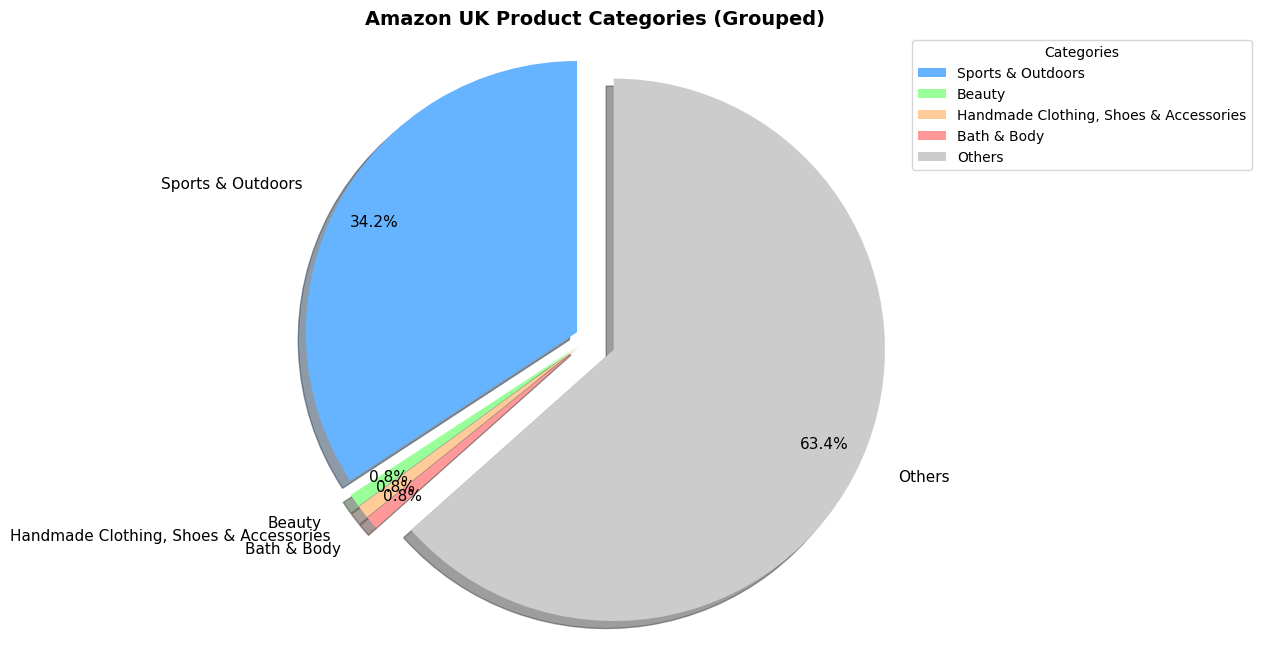

In [21]:

import matplotlib.pyplot as plt

category_counts = df['category'].value_counts()    # df['category'] selects the 'category' column from the dataframe.
                                                   # .value_counts() counts how many listings exist for each unique category,
                                                   # returning a Series where:
                                                   # index = category name
                                                   # value = frequency (number of listings)

top4 = category_counts.head(4)                     # .head(4) selects the first 4 rows (the 4 most frequent categories).
others = category_counts.iloc[4:].sum()            # .iloc[4:] selects all remaining categories from position 4 onwards (the smaller ones).
                                                   # .sum() adds up all their counts to create one combined number.

pie_data = pd.concat([top4, pd.Series({'Others': others})])  # pd.concat() joins two or more pandas Series together vertically.
                                                             # Here we join the 'top4' categories with a new Series containing just one entry: "Others".
                                                             # The resulting object is a Series where:
                                                             #   - index = ['Category1', 'Category2', 'Category3', 'Category4', 'Others']
                                                             #   - values = their respective listing counts

explode = [0.05 if i < len(pie_data) - 1 else 0.1 for i in range(len(pie_data))]  #'explode' is a list of offset values for each slice in the pie chart.
                                                                                  # The expression [0.05 if i < len(pie_data)-1 else 0.1 ...] means:
                                                                                  #   - for all slices except the last one ("Others"), offset by 0.05 (small gap)
                                                                                  #   - for the last slice ("Others"), offset by 0.1 (a bit more separation)
                                                                                  # This visually emphasizes the "Others" category.

plt.figure(figsize=(8,8))          # plt.figure() creates a new blank figure where the chart will be drawn.
                                   # figsize=(8,8) sets both width and height to 8 inches, giving a square shape
                                   # — important for keeping the pie chart perfectly round and giving labels room to breathe.

pie_data.plot(
    kind='pie',                          # The 'kind' parameter tells pandas what type of chart to make.
                                         # Here we specify 'pie', which automatically converts the Series into a pie chart.
                                         # Internally, pandas calls matplotlib.pyplot.pie() behind the scenes.

    autopct='%1.1f%%',                   # The 'autopct' parameter controls the format of the percentage labels
                                         # displayed on each slice of the pie.
                                         # '%1.1f%%' means:
                                         #   - %f : print a floating-point number (a decimal)
                                         #   - 1.1 : show 1 digit before and 1 digit after the decimal point
                                         #   - %% : the double percentage signs escape the '%' symbol
                                         # So, 23.4% will be shown as "23.4%"
                                         # If you change it to '%d%%', you’d only see integers (e.g., "23%").

    startangle=90,                       # This rotates the starting position of the first slice by 90 degrees.
                                         # By default, pie charts start at 0° (which corresponds to the positive x-axis, i.e., the right side).
                                         # Rotating by 90° makes the first slice start at the top, which looks more balanced visually.

    colors=['#66b3ff', '#99ff99', '#ffcc99', '#ff9999', '#cccccc'],  # color palette 
                                                                                # https://matplotlib.org/stable/users/explain/colors/colors.html#colors-def
                                                                                # Hex color codes can be found in the link above
    explode=explode,                     # 'explode' defines how far each slice is pulled out from the center.
                                         # It takes a list of numeric values, where each number represents the fraction of the radius
                                         # to shift that slice outward.
                                         # For example, if explode = [0, 0, 0.1, 0, 0]:
                                         #   - the 3rd slice would move 10% of the pie’s radius away from the center.
                                         #   - all others remain in place.
                                         # In our case, "explode" is defined above as:
                                         #   explode = [0.05, 0.05, 0.05, 0.05, 0.1]
                                         # meaning each major slice moves slightly, while "Others" is pulled out a bit more (0.1).

    shadow=True,                         # Adds a soft shadow effect underneath the pie chart.
                                         # It gives the chart a bit of depth and helps distinguish overlapping slices
                                         # Default is False, meaning no shadow.
    
    ylabel='',                           # remove auto y-label
    labeldistance=1.15,                  # push labels outside the pie
    pctdistance=0.85,                    # push percentage text outward
    
    textprops={'fontsize': 11, 'color': 'black'}  # 'textprops' is a dictionary that customizes how text elements look.
                                                  # You can control font size, color, weight, style, and alignment.
                                                  # Here:
                                                  #   - fontsize=11 makes both percentages and labels readable but not too large.
                                                  #   - color='black' ensures good contrast against light slice colors.
                                                  # Other useful text options include:
                                                  #   fontweight='bold', rotation=angle, ha='center', va='center'
)

plt.title('Amazon UK Product Categories (Grouped)', fontsize=14, fontweight='bold')  # plt.title() adds a descriptive title above the chart.
                                                                                     # fontsize=14 makes it large and readable, and fontweight='bold' emphasizes it.

plt.axis('equal')      # plt.axis('equal') ensures that the pie chart is drawn as a circle (not an ellipse).
                       # This keeps the proportions visually accurate.

plt.legend(labels=pie_data.index, title='Categories', loc='upper left', bbox_to_anchor=(1,1))  # plt.legend() adds a legend box explaining which color corresponds to each category.
                                                                                               # labels=pie_data.index ensures the legend shows the actual category names.
                                                                                               # title adds a header inside the legend box.
                                                                                               # loc and bbox_to_anchor position the legend neatly outside the pie chart.

plt.show()  # Display the chart


### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

In [23]:
# 1. Measures of Centrality - Price Distribution

import numpy as np

mean_price = df['price'].mean()       # .mean() calculates the arithmetic average:
                                      # sum of all prices ÷ number of products.

median_price = df['price'].median()   # .median() finds the middle value when all prices are sorted.
                                      # It’s less sensitive to extreme values (outliers) than the mean.

mode_price = df['price'].mode()[0]    # .mode() returns the most frequently occurring price value.
                                      # We use [0] because .mode() returns a Series (it can have multiple modes).

print("Average (Mean) Price:", round(mean_price, 2))
print("Median Price:", round(median_price, 2))
print("Most Common (Mode) Price:", round(mode_price, 2))



Average (Mean) Price: 89.24
Median Price: 19.09
Most Common (Mode) Price: 9.99


In [ ]:
# 2. Measures of Dispersion - Price Variability

variance_price = df['price'].var()     # Variance
                                       # Variance shows how much prices differ from the mean on average.
                                       # A higher variance means prices are widely spread out.

std_price = df['price'].std()          # Standard Deviation
                                       # The square root of variance. It’s in the same unit as the original data (price).

price_range = df['price'].max() - df['price'].min()   # Range
                                                      # The difference between the maximum and minimum price.

# Interquartile Range (IQR) - It’s especially useful when data is skewed (like prices)

Q1 = df['price'].quantile(0.25)  # .quantile(0.25) gives the value below which 25% of the data falls.
                                 # In other words, 25% of product prices are less than or equal to this number.
                                 # This represents the "lower bound" of the middle 50% of data.

Q3 = df['price'].quantile(0.75)  # .quantile(0.75) gives the value below which 75% of the data falls.
                                 # That means 75% of all products are priced below this value,
                                 # and the remaining 25% are priced above it.
                                 # Q3 marks the "upper bound" of the middle 50% of prices.

iqr_price = Q3 - Q1              # Subtract Q1 from Q3 to find the spread of the middle 50% of the data.
                                 # Mathematically: IQR = Q3 - Q1
                                 # This tells us how wide the central portion of the price distribution is.
                                 # A small IQR → prices are concentrated near the median.
                                 # A large IQR → prices vary widely even among typical products.

print("Price Variance:", round(variance_price, 2))   # variance_price → This is a variable we calculated earlier using:
                                                     # variance_price = df['price'].var()
                                                     # It represents the average of squared differences from the mean.
                                                     #    round(variance_price, 2) → The round() function limits the numeric output
                                                     #                             to 2 decimal places for readability.
                                                     #                             Example: 342.456728 → 342.46

print("Price Standard Deviation:", round(std_price, 2))            # std_price = df['price'].std()
                                                                   # This is the square root of the variance.
                                                                   # It represents the **average deviation from the mean in actual currency units (e.g., £)**.
                                                                   # round(std_price, 2) → Rounded to two decimals, same reasoning as above.

print("Price Range:", round(price_range, 2))                       # price_range = df['price'].max() - df['price'].min()
                                                                   # This subtracts the minimum price from the maximum price.
                                                                   # It represents the **total spread** of prices in the dataset.

print("Price Interquartile Range (IQR):", round(iqr_price, 2))


Price Variance: 119445.49
Price Standard Deviation: 345.61
Price Range: 100000.0
Price Interquartile Range (IQR): 36.0


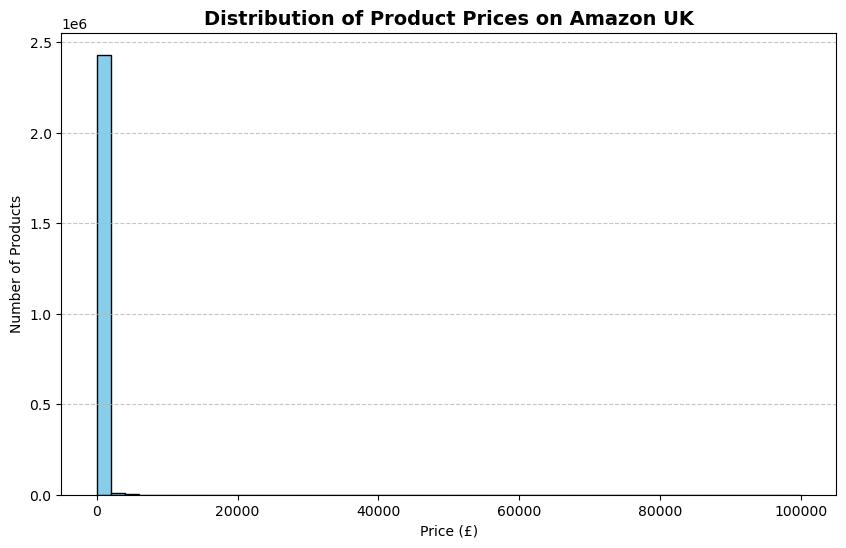

In [26]:
# 3. Visualizing Price distribuiton - Histogram

import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.hist(df['price'], bins=50, color='skyblue', edgecolor='black')
plt.title('Distribution of Product Prices on Amazon UK', fontsize=14, fontweight='bold')
plt.xlabel('Price (£)')
plt.ylabel('Number of Products')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


Hisotgram is hard to read due to the fact that:

- Most of products are priced at low values (close to £0–£100).

- But a few products have extremely high prices — like £10,000 or even £100,000.

- These outliers stretch the x-axis, so all normal prices get compressed into one narrow bar.

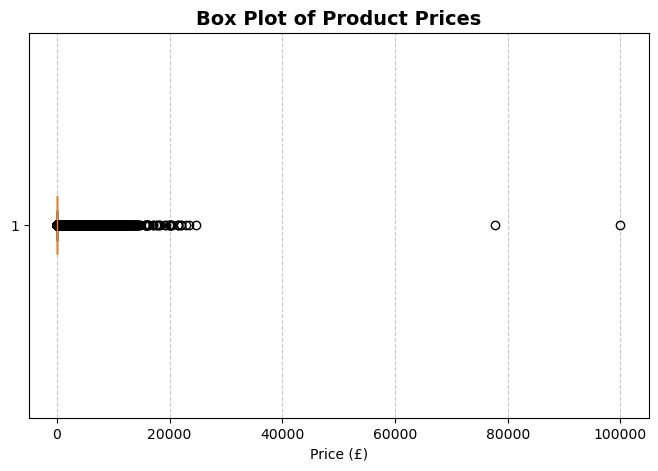

In [27]:
# 3.b Box Plot - Detecting Outliers

plt.figure(figsize=(8,5))

plt.boxplot(df['price'], vert=False, patch_artist=True, boxprops=dict(facecolor='lightblue'))

plt.title('Box Plot of Product Prices', fontsize=14, fontweight='bold')
plt.xlabel('Price (£)')

plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()


Brief Explanation of What You’re Seeing

- The orange box is barely visible on the left, meaning almost all products are clustered at very low prices (close to £0–£200).
- The horizontal black circles far to the right (around £20k–£100k) are extreme outliers — very expensive listings that are completely outside the normal range.
- The whiskers (the thin lines extending from the box) show the typical variation — but since there are so many low-priced products, the scale stretches so far that the box itself gets visually “squashed” on the left.

In short: the distribution is highly right-skewed, meaning the dataset has a long tail of a few very expensive items.


Business Takeaway

- The Amazon UK marketplace is dominated by affordable products, with a small number of luxury or mispriced items inflating the upper range.
- The main consumer price band lies at the very low end — that’s the true competitive zone.


Upsides
- The outliers could represent premium opportunities (e.g., specialized or collectible goods) or data anomalies (e.g., listing errors).
- Relying on averages (mean) can be misleading here, since they’re pulled up by these extreme values.

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?


In [ ]:
# 1. MEASURES OF CENTRALITY — PRODUCT RATINGS

mean_rating = df['stars'].mean()

median_rating = df['stars'].median()

mode_rating = df['stars'].mode()[0]

print("Average (Mean) Rating:", round(mean_rating, 2))
print("Median Rating:", round(median_rating, 2))
print("Most Common (Mode) Rating:", round(mode_rating, 2))



Average (Mean) Rating: 2.15
Median Rating: 0.0
Most Common (Mode) Rating: 0.0


In [ ]:
print(df.columns.tolist())


['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller', 'boughtInLastMonth', 'category']


In [32]:
# 2. MEASURES OF DISPERSION — VARIABILITY OF RATINGS

variance_rating = df['stars'].var()       # Variance tells us the **average squared difference** between each rating and the mean rating.
                                          # If the variance is low → most ratings are close to the mean.
                                          # If it’s high → ratings vary widely (some customers love, some hate).

std_rating = df['stars'].std()            # Standard deviation is simply the square root of the variance.
                                          # It gives us the average difference from the mean in the same unit as the data (rating points).
                                          # A low std (e.g., 0.4) = customers mostly agree.
                                          # A high std (e.g., 1.5) = large disagreement.

Q1_rating = df['stars'].quantile(0.25)    # Q1 = 25th percentile → 25% of products have a lower rating than this.

Q3_rating = df['stars'].quantile(0.75)    # Q3 = 75th percentile → 75% of products have a lower rating than this.

iqr_rating = Q3_rating - Q1_rating        # The IQR measures the spread of the middle 50% of the ratings (between Q1 and Q3).

print("Rating Variance:", round(variance_rating, 3))
print("Rating Standard Deviation:", round(std_rating, 3))
print("Rating Interquartile Range (IQR):", round(iqr_rating, 3))
print("Q1 (25th Percentile):", round(Q1_rating, 2))
print("Q3 (75th Percentile):", round(Q3_rating, 2))


Rating Variance: 4.817
Rating Standard Deviation: 2.195
Rating Interquartile Range (IQR): 4.4
Q1 (25th Percentile): 0.0
Q3 (75th Percentile): 4.4


In [ ]:
# 3. SHAPE OF DISTRIBUTION — SKEWNESS & KURTOSIS

from scipy.stats import skew, kurtosis
# Imports the necessary functions from scipy.stats
# 'scipy' is a scientific computing library; 'skew' and 'kurtosis'
# it will help us calculate the asymmetry and peakedness of our data distribution.


skewness_rating = skew(df['stars'].dropna())         # Skewness measures how symmetric or lopsided your data is.
                                                     #  → 0 means the data is perfectly symmetrical (e.g., a bell curve).
                                                     #  → Positive skew (>0): the "tail" is longer on the right → more low ratings.
                                                     #  → Negative skew (<0): the "tail" is longer on the left → more high ratings.
                                                     # For Amazon ratings, we expect **negative skewness** because most customers
                                                     # tend to give products 4 or 5 stars, with very few low ratings.


kurtosis_rating = kurtosis(df['stars'].dropna())     # Kurtosis measures how "peaked" or "flat" your distribution is.
                                                     #  → 0 means normal bell-shaped distribution.
                                                     #  → Positive kurtosis (>0): distribution is sharply peaked (most values cluster near the mean).
                                                     #  → Negative kurtosis (<0): flatter distribution (ratings spread more evenly).
                                                     # A high kurtosis (>3 using Fisher’s definition) indicates that many ratings are close
                                                     # to the same value (e.g., everyone gives 5 stars).


print("Skewness of Ratings:", round(skewness_rating, 2))
print("Kurtosis of Ratings:", round(kurtosis_rating, 2))


Skewness of Ratings: 0.08
Kurtosis of Ratings: -1.93


**Interpretation:**

**Skewness = +0.08**

This value is very close to 0, which means the ratings are almost perfectly symmetrical.

Therefore:

- The distribution of ratings isn’t heavily “right-tailed” (too many low ratings),

- Nor “left-tailed” (too many 5-star ratings).

Customers give ratings that are evenly spread, perhaps between 3–5 stars — a balanced sentiment.



**Kurtosis = –1.93**

Negative kurtosis means the distribution is flatter than a normal bell curve.

There’s less concentration around the mean and more ratings spread out across different values.

Therefore:

- Ratings are not tightly clustered around one value like 4 or 5.

- There’s a healthy diversity in how customers rate products — some rate high, some moderate, some low.

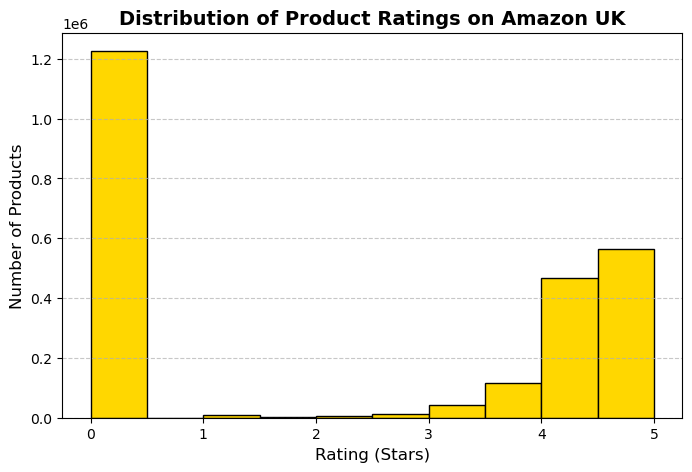

In [ ]:
# 4. VISUALIZATION — HISTOGRAM OF PRODUCT RATINGS

import matplotlib.pyplot as plt


plt.figure(figsize=(8,5))       # Create a new figure to ensure a clean plot
                                # figsize controls the dimensions (width x height) of the chart in inches.


plt.hist(df['stars'], bins=10, color='gold', edgecolor='black')     # plt.hist() divides all ratings into "bins" (intervals) and counts how many products fall into each bin.
                                                                    # bins=10 → splits ratings roughly into 0.5-point intervals from 0 to 5
                                                                    # color='gold' → fills bars with golden color (visually clear)
                                                                    # edgecolor='black' → outlines each bar so they’re easier to distinguish

plt.title('Distribution of Product Ratings on Amazon UK', fontsize=14, fontweight='bold') 
plt.xlabel('Rating (Stars)', fontsize=12)
plt.ylabel('Number of Products', fontsize=12)


plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()
